# Figures pipeline — Latent Variable Identification PISA 2022

Notebook dedicado a la generación de todas las figuras del artículo.
No realiza análisis — solo lee los outputs de los pasos 1-6 y genera figuras en alta resolución.

**Outputs generados:**
- `fig2a_heatmap_efa_estudiante_rural.png`
- `fig2b_heatmap_efa_escuela_b_rural.png`
- `fig3_irt_discriminacion_rural.png`
- `fig4_lca_bic_entropia.png`
- `fig5_heatmap_perfiles_clases_rural.png`
- `fig6_contexto_clases_rural.png`
- `fig7_comparativa_nacional_rural.png`

## 0. Configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# ── Rutas de inputs ───────────────────────────────────────────────────────────
# Ajusta estas rutas si tus archivos están en otra carpeta
RUTA_BASE_RURAL    = "/workspace/data/output_rural/"   # carpeta donde están los outputs del pipeline rural
RUTA_BASE_NACIONAL = "/workspace/data/output/"   # carpeta donde están los outputs del pipeline nacional
RUTA_FIGURAS       = "/workspace/notebooks_rural/04_graphics/figuras_articulo/"  # carpeta de salida de figuras

import os
os.makedirs(RUTA_FIGURAS, exist_ok=True)

# ── Estilo global ─────────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi"        : 300,
    "savefig.dpi"       : 300,
    "savefig.bbox"      : "tight",
    "savefig.facecolor" : "white",
    "font.family"       : "sans-serif",
    "font.size"         : 9,
    "axes.titlesize"    : 10,
    "axes.labelsize"    : 9,
    "xtick.labelsize"   : 8,
    "ytick.labelsize"   : 8,
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
})

# Paleta de colores del artículo
COLOR_NACIONAL = "#0C447C"
COLOR_RURAL    = "#085041"
COLOR_ACCENT   = "#633806"

print(f"Carpeta de figuras: {RUTA_FIGURAS}")
print("Configuración lista.")

Carpeta de figuras: /workspace/notebooks_rural/04_graphics/figuras_articulo/
Configuración lista.


## FIGURA 2a — Heatmap cargas EFA bloque Estudiante (rural)

In [5]:
# Cargar cargas EFA rural
df_cargas = pd.read_csv(RUTA_BASE_RURAL + "efa_cargas_factoriales.csv", index_col=0)

# Nombres interpretativos de factores — bloque estudiante rural
NOMBRES_FACTORES_STU = {
    "F1_estudiante" : "F1 Capital cultural",
    "F2_estudiante" : "F2 Estrategias mat.",
    "F3_estudiante" : "F3 Recursos digitales",
    "F4_estudiante" : "F4 Pertenencia escolar",
    "F5_estudiante" : "F5 Violencia escolar",
    "F6_estudiante" : "F6 Participacion mat.",
    "F7_estudiante" : "F7 Relaciones pares",
    "F8_estudiante" : "F8 Educ. padres",
    "F9_estudiante" : "F9 Autoconcepto mat.",
    "F10_estudiante": "F10 Act. extracurric.",
}

# Filtrar bloque estudiante — solo ítems seleccionados
df_stu = df_cargas[
    (df_cargas["bloque"] == "estudiante") &
    (df_cargas["seleccionado"] == True)
].copy()

cols_factores_stu = [c for c in NOMBRES_FACTORES_STU.keys() if c in df_stu.columns]
df_plot_stu = df_stu[cols_factores_stu].copy()
df_plot_stu.columns = [NOMBRES_FACTORES_STU[c] for c in cols_factores_stu]

# Ordenar ítems por factor dominante
factor_dominante = df_plot_stu.abs().idxmax(axis=1)
df_plot_stu["_factor"] = factor_dominante
df_plot_stu = df_plot_stu.sort_values("_factor").drop(columns="_factor")

print(f"Ítems bloque estudiante: {df_plot_stu.shape[0]}")
print(f"Factores: {df_plot_stu.shape[1]}")

Ítems bloque estudiante: 47
Factores: 10


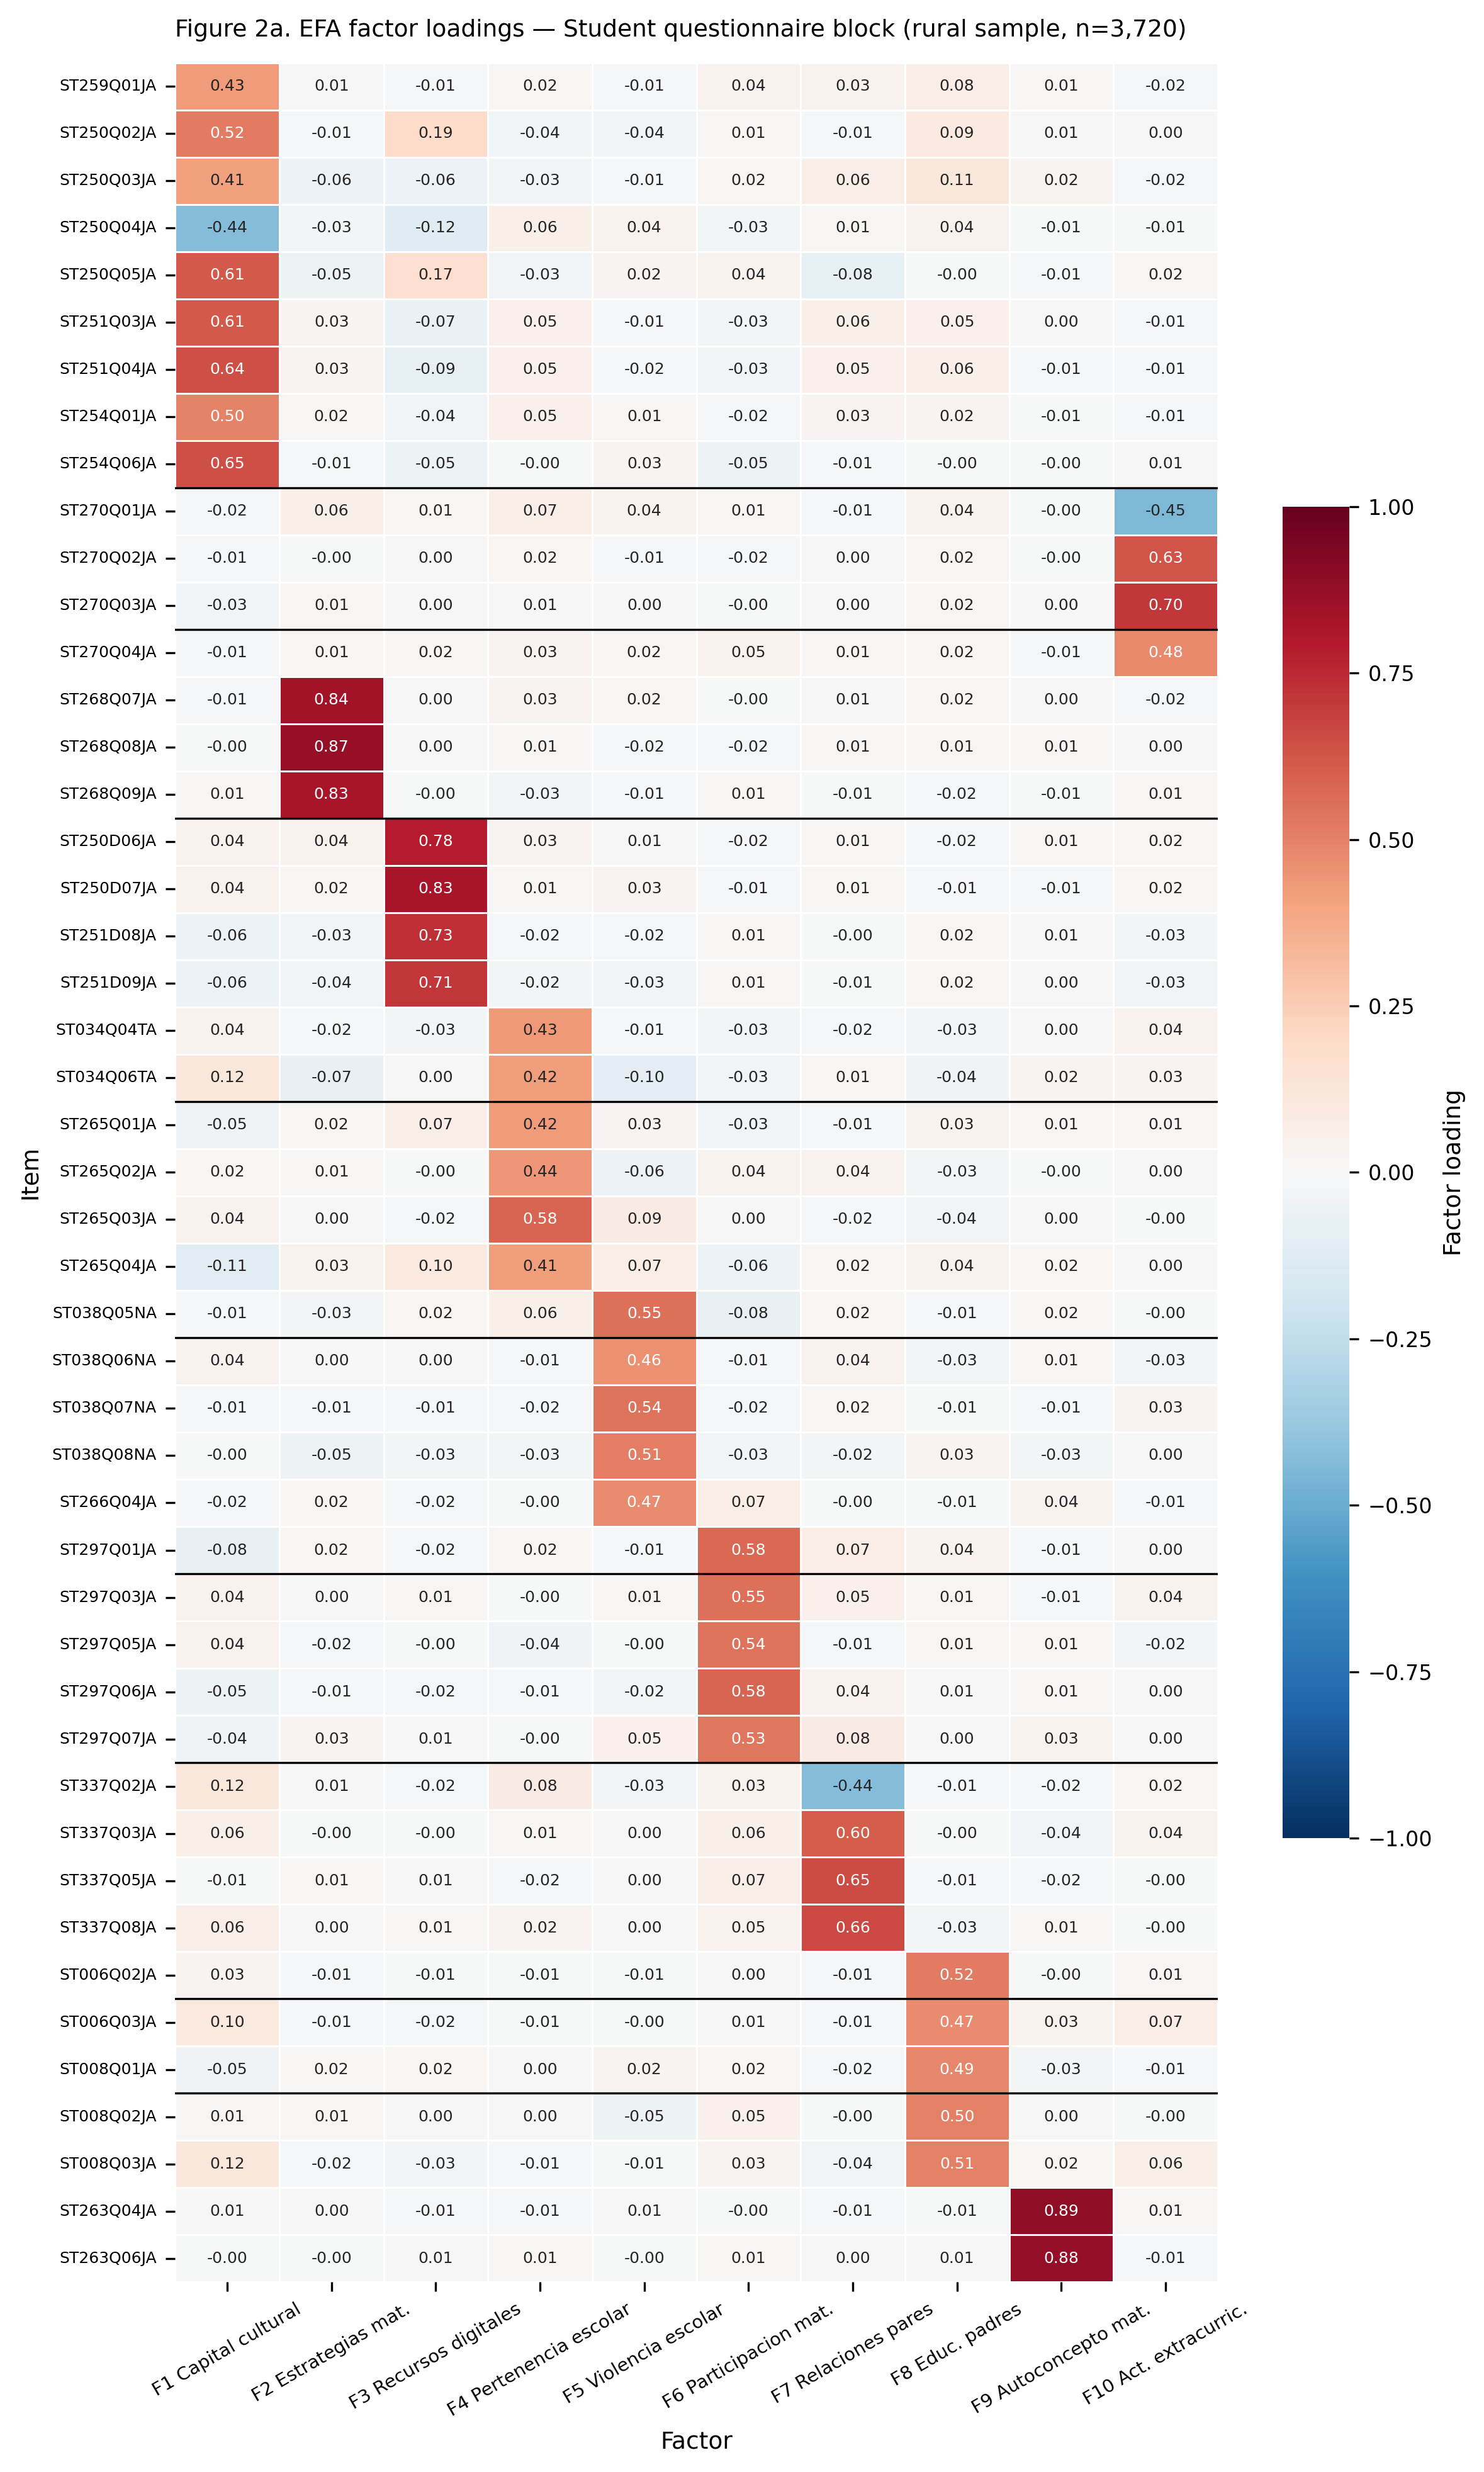

Guardado: /workspace/notebooks_rural/04_graphics/figuras_articulo/fig2a_heatmap_efa_estudiante_rural.png


In [6]:
altura = max(8, df_plot_stu.shape[0] * 0.28)
fig, ax = plt.subplots(figsize=(8, altura))

sns.heatmap(
    df_plot_stu,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    linecolor="white",
    annot_kws={"size": 6},
    cbar_kws={"label": "Factor loading", "shrink": 0.6},
    ax=ax,
)

ax.set_title(
    "Figure 2a. EFA factor loadings — Student questionnaire block (rural sample, n=3,720)",
    fontsize=9, pad=10, loc="left"
)
ax.set_xlabel("Factor", fontsize=9)
ax.set_ylabel("Item", fontsize=9)
ax.tick_params(axis="x", rotation=30, labelsize=7)
ax.tick_params(axis="y", labelsize=6)

# Línea separadora entre grupos de factores
items_por_factor = df_plot_stu.abs().idxmax(axis=1).value_counts()
pos_acum = 0
for col in df_plot_stu.columns:
    n = (df_plot_stu.abs().idxmax(axis=1) == col).sum()
    pos_acum += n
    if pos_acum < df_plot_stu.shape[0]:
        ax.axhline(pos_acum, color="black", linewidth=0.8, linestyle="-")

plt.tight_layout()
ruta_fig = RUTA_FIGURAS + "fig2a_heatmap_efa_estudiante_rural.png"
plt.savefig(ruta_fig)
plt.show()
print(f"Guardado: {ruta_fig}")

## FIGURA 2b — Heatmap cargas EFA bloque Escuela B (rural)

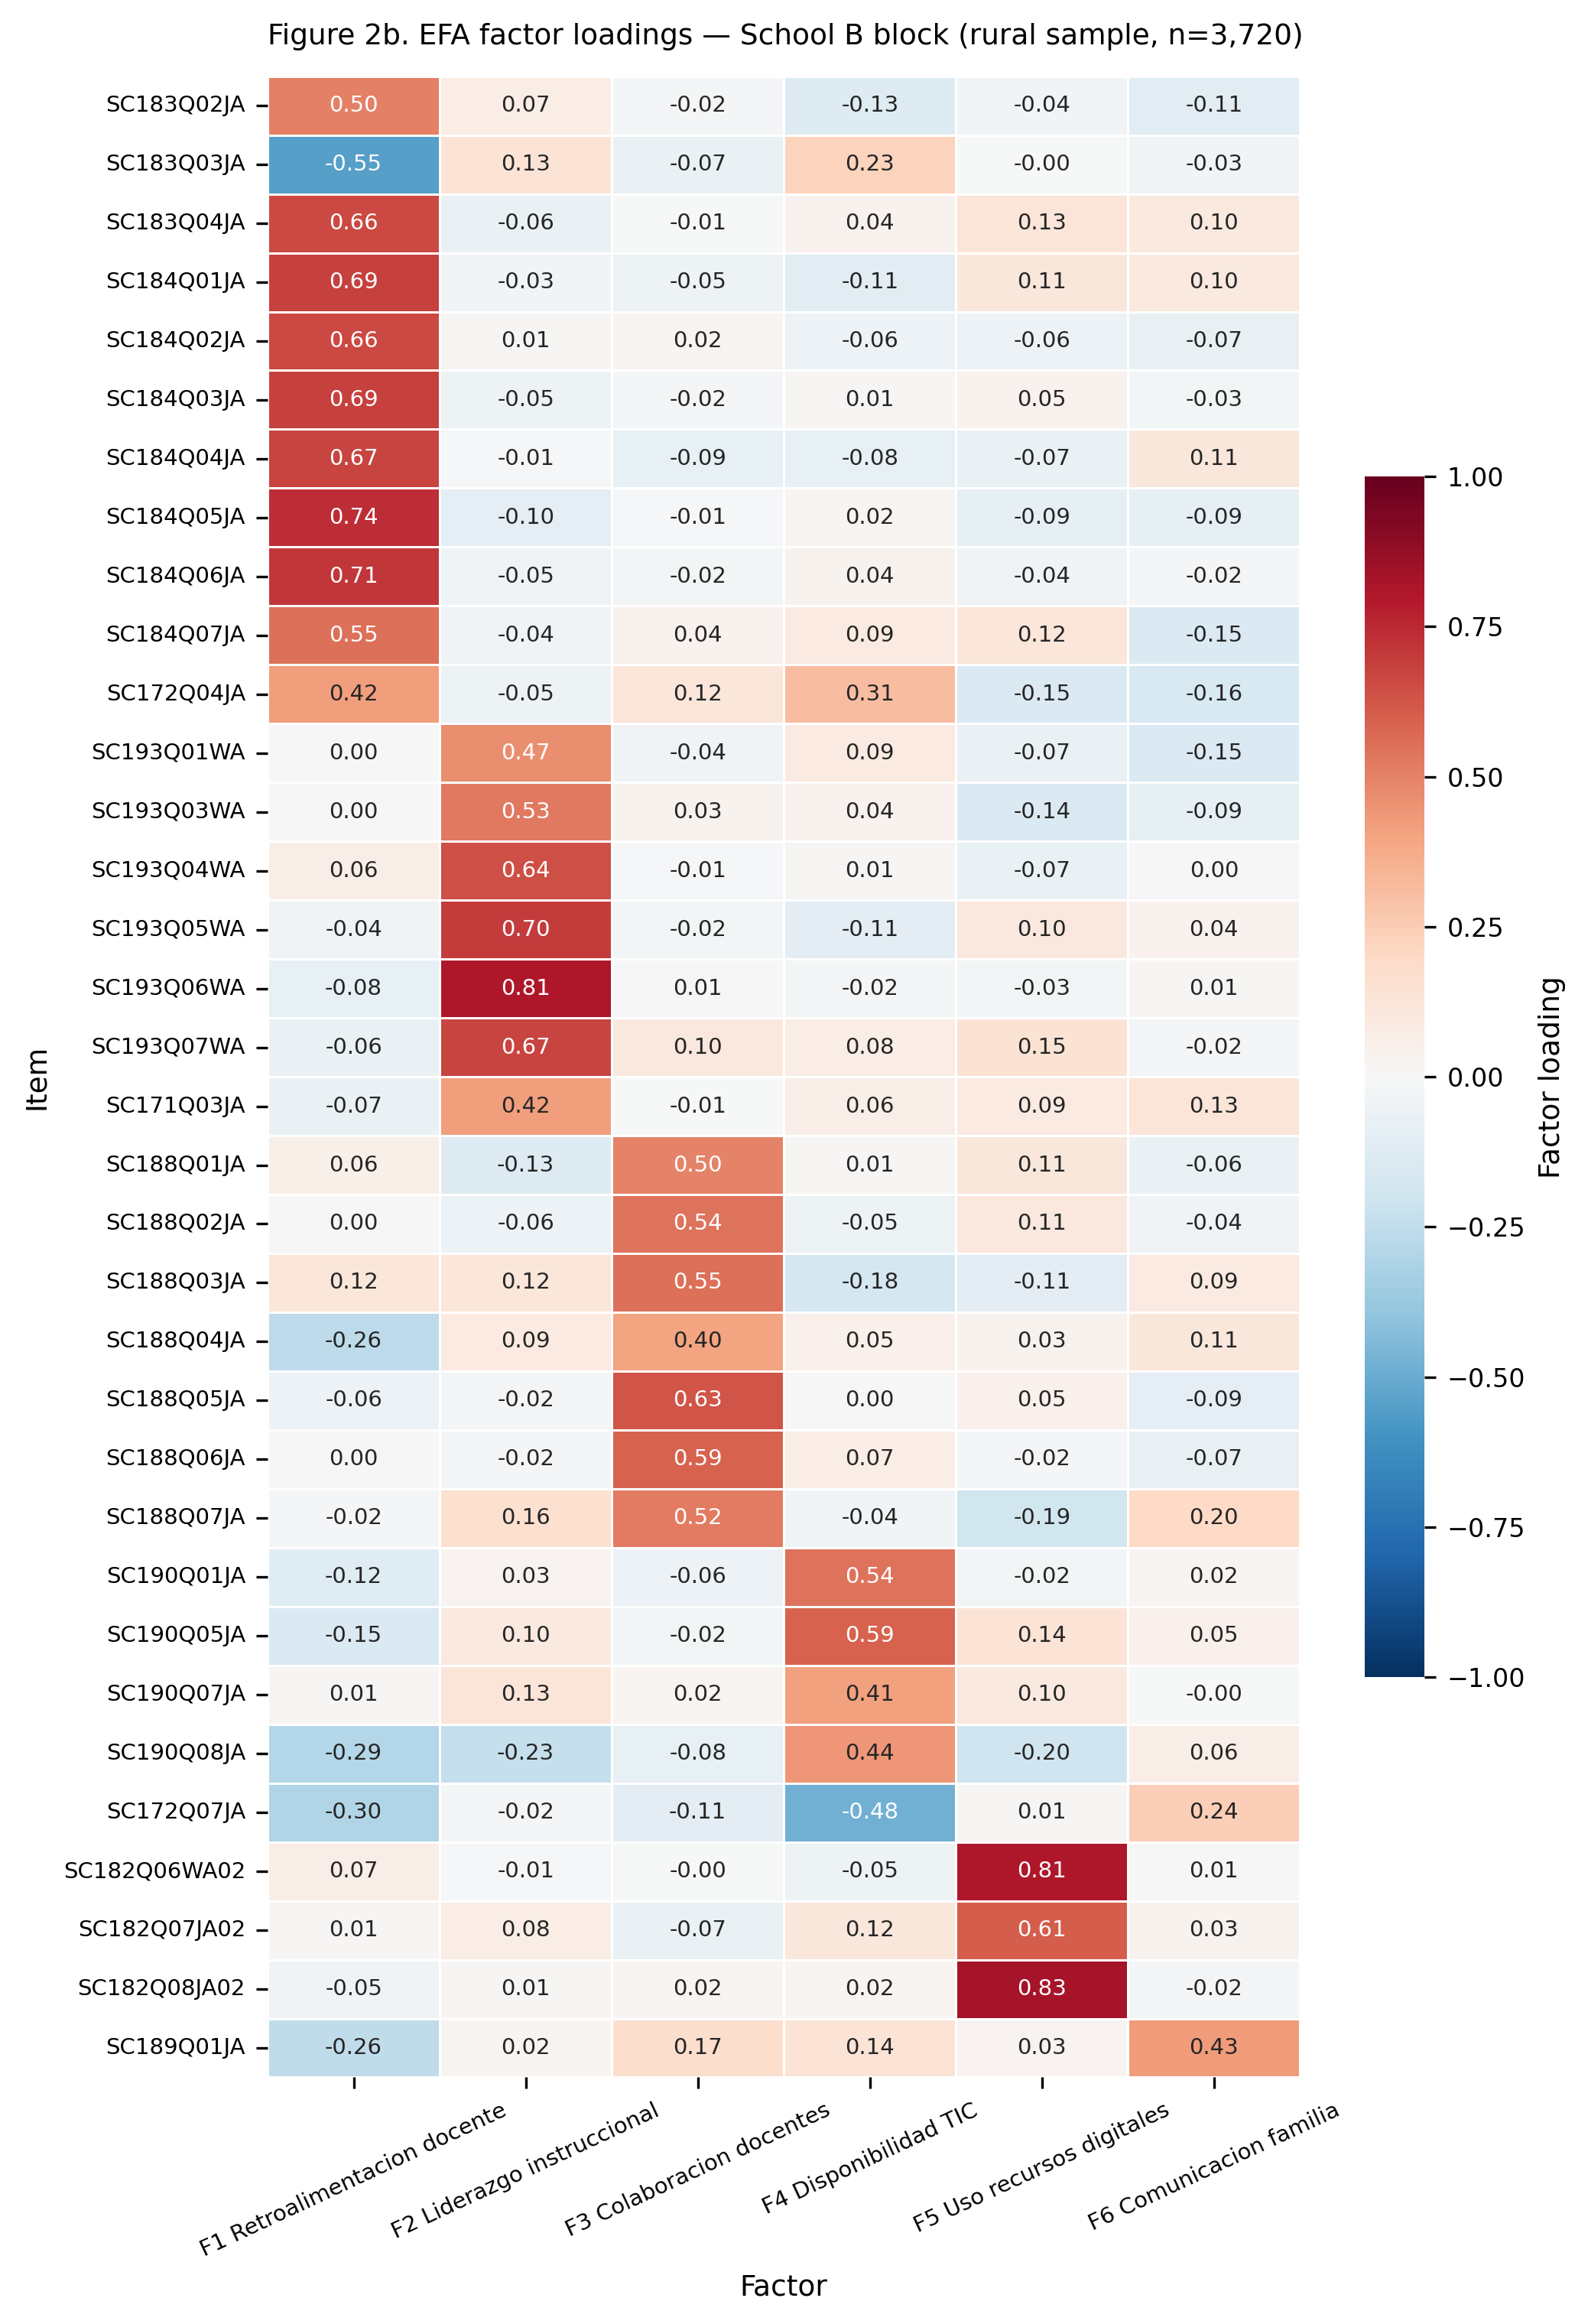

Guardado: /workspace/notebooks_rural/04_graphics/figuras_articulo/fig2b_heatmap_efa_escuela_b_rural.png


In [7]:
NOMBRES_FACTORES_SCH = {
    "F1_escuela_b" : "F1 Retroalimentacion docente",
    "F2_escuela_b" : "F2 Liderazgo instruccional",
    "F3_escuela_b" : "F3 Colaboracion docentes",
    "F4_escuela_b" : "F4 Disponibilidad TIC",
    "F5_escuela_b" : "F5 Uso recursos digitales",
    "F6_escuela_b" : "F6 Comunicacion familia",
}

df_sch = df_cargas[
    (df_cargas["bloque"] == "escuela_b") &
    (df_cargas["seleccionado"] == True)
].copy()

cols_factores_sch = [c for c in NOMBRES_FACTORES_SCH.keys() if c in df_sch.columns]
df_plot_sch = df_sch[cols_factores_sch].copy()
df_plot_sch.columns = [NOMBRES_FACTORES_SCH[c] for c in cols_factores_sch]

factor_dominante_sch = df_plot_sch.abs().idxmax(axis=1)
df_plot_sch["_factor"] = factor_dominante_sch
df_plot_sch = df_plot_sch.sort_values("_factor").drop(columns="_factor")

altura_sch = max(6, df_plot_sch.shape[0] * 0.30)
fig, ax = plt.subplots(figsize=(7, altura_sch))

sns.heatmap(
    df_plot_sch,
    annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    linewidths=0.3, linecolor="white",
    annot_kws={"size": 7},
    cbar_kws={"label": "Factor loading", "shrink": 0.6},
    ax=ax,
)

ax.set_title(
    "Figure 2b. EFA factor loadings — School B block (rural sample, n=3,720)",
    fontsize=9, pad=10, loc="left"
)
ax.set_xlabel("Factor", fontsize=9)
ax.set_ylabel("Item", fontsize=9)
ax.tick_params(axis="x", rotation=25, labelsize=7)
ax.tick_params(axis="y", labelsize=7)

plt.tight_layout()
ruta_fig = RUTA_FIGURAS + "fig2b_heatmap_efa_escuela_b_rural.png"
plt.savefig(ruta_fig)
plt.show()
print(f"Guardado: {ruta_fig}")

## FIGURA 3 — Distribución de discriminación IRT (rural vs nacional)

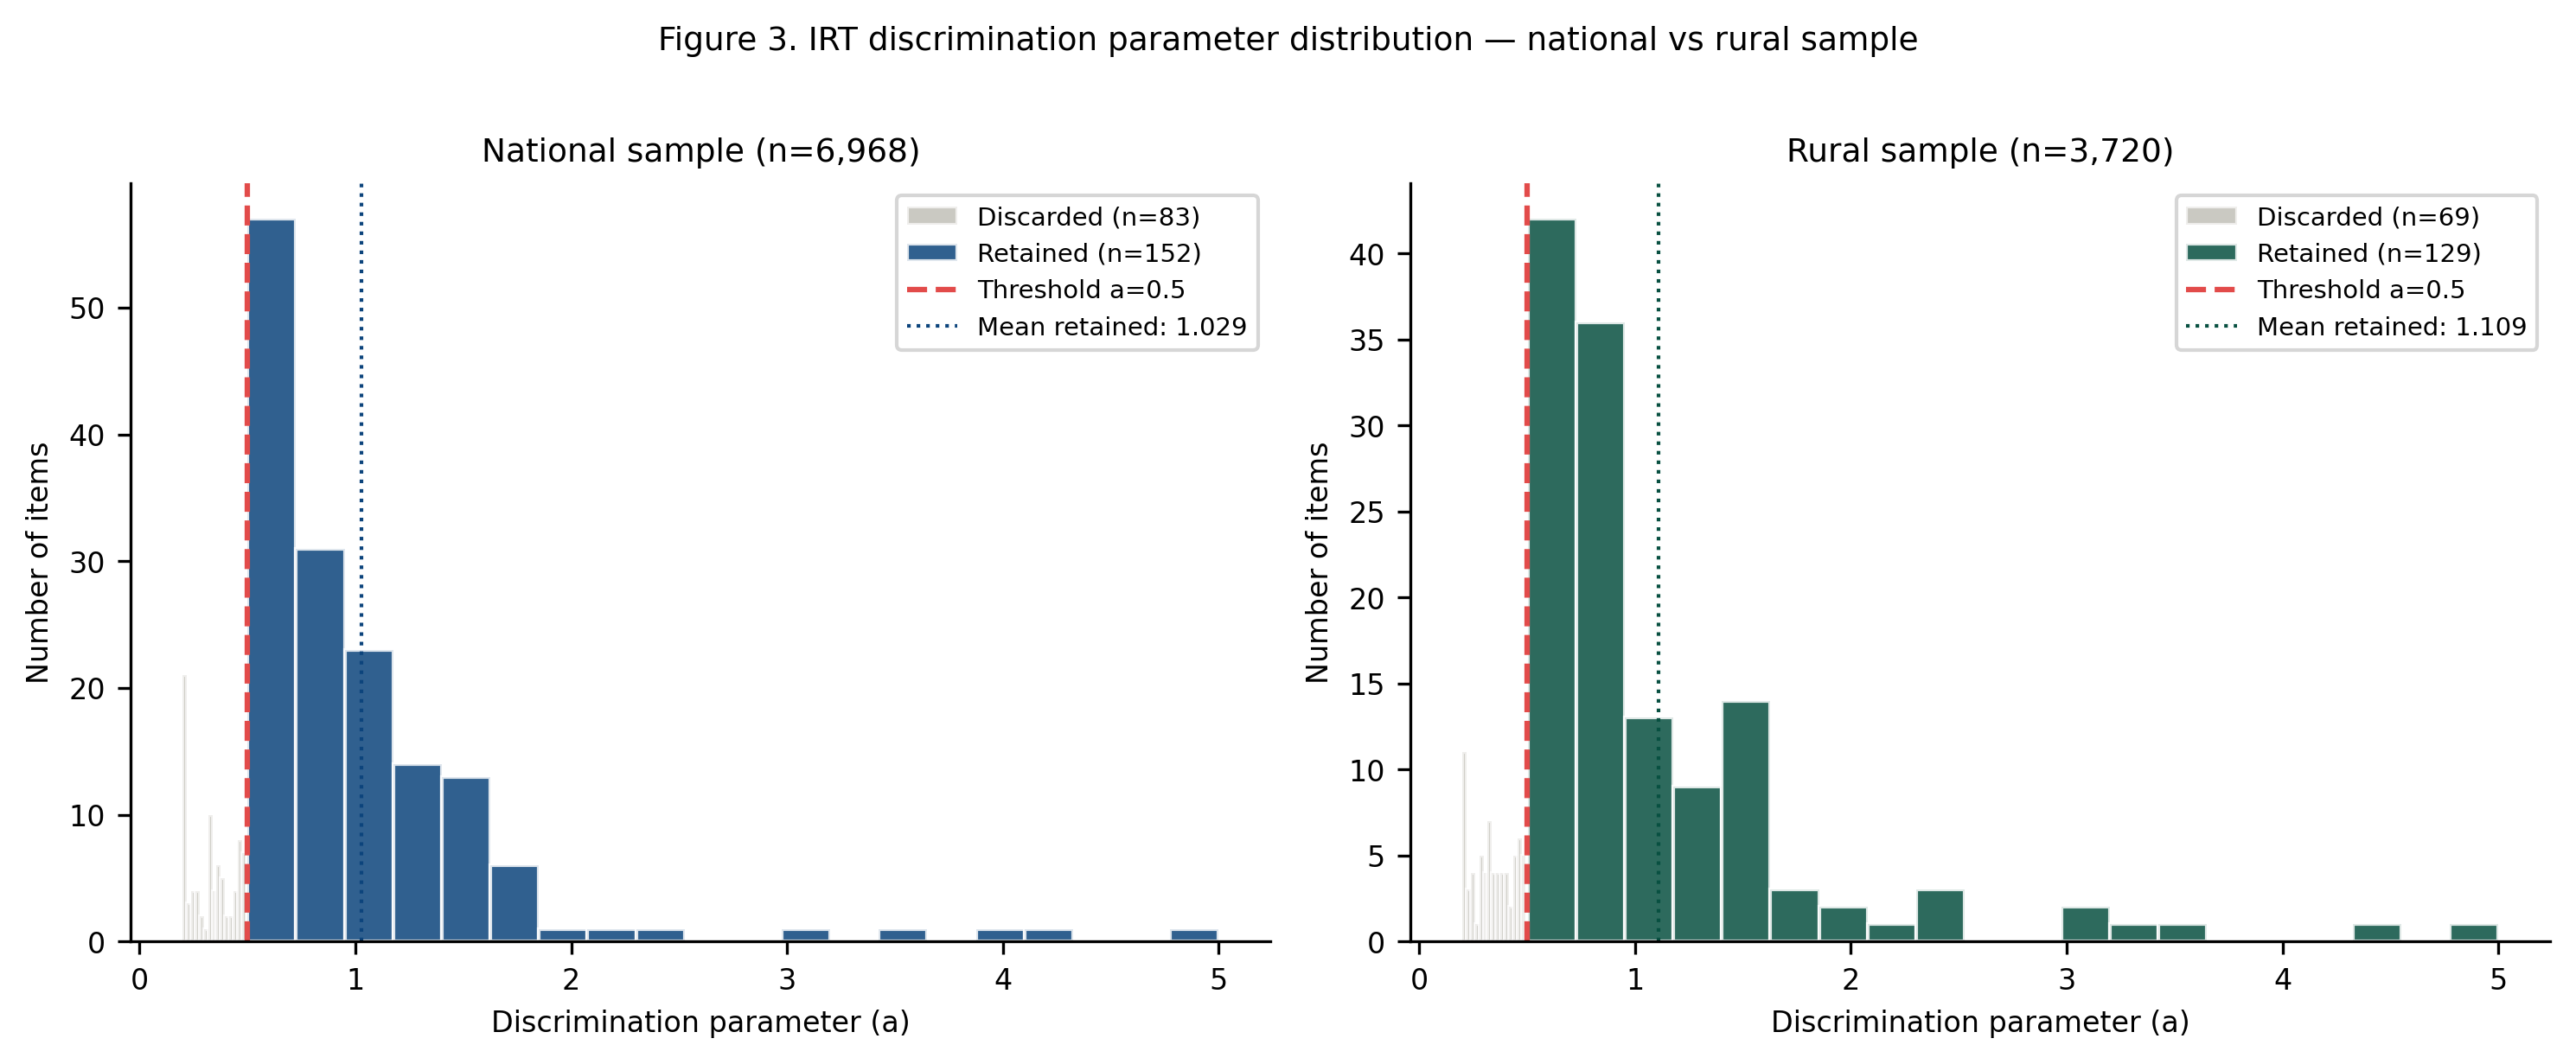

Guardado: /workspace/notebooks_rural/04_graphics/figuras_articulo/fig3_irt_discriminacion_rural_nacional.png


In [10]:
df_irt_rural    = pd.read_csv(RUTA_BASE_RURAL    + "irt_parametros_todos.csv")
df_irt_nacional = pd.read_csv(RUTA_BASE_NACIONAL + "irt_parametros_todos.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)

for ax, df_irt, label, color, umbral in [
    (axes[0], df_irt_nacional, "National sample (n=6,968)", COLOR_NACIONAL, 0.50),
    (axes[1], df_irt_rural,    "Rural sample (n=3,720)",    COLOR_RURAL,    0.50),
]:
    retenidos  = df_irt[df_irt["discriminacion"] >= umbral]["discriminacion"]
    descartados = df_irt[df_irt["discriminacion"] < umbral]["discriminacion"]

    ax.hist(descartados, bins=15, color="#B4B2A9", alpha=0.7,
            edgecolor="white", label=f"Discarded (n={len(descartados)})")
    ax.hist(retenidos,   bins=20, color=color,     alpha=0.85,
            edgecolor="white", label=f"Retained (n={len(retenidos)})")
    ax.axvline(umbral, color="#E24B4A", linewidth=1.5,
               linestyle="--", label=f"Threshold a={umbral}")
    ax.axvline(df_irt[df_irt["discriminacion"] >= umbral]["discriminacion"].mean(),
               color=color, linewidth=1, linestyle=":",
               label=f"Mean retained: {retenidos.mean():.3f}")
    ax.set_title(label, fontsize=9)
    ax.set_xlabel("Discrimination parameter (a)", fontsize=8)
    ax.set_ylabel("Number of items", fontsize=8)
    ax.legend(fontsize=7)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Figure 3. IRT discrimination parameter distribution — national vs rural sample",
    fontsize=9, y=1.01
)
plt.tight_layout()
ruta_fig = RUTA_FIGURAS + "fig3_irt_discriminacion_rural_nacional.png"
plt.savefig(ruta_fig)
plt.show()
print(f"Guardado: {ruta_fig}")

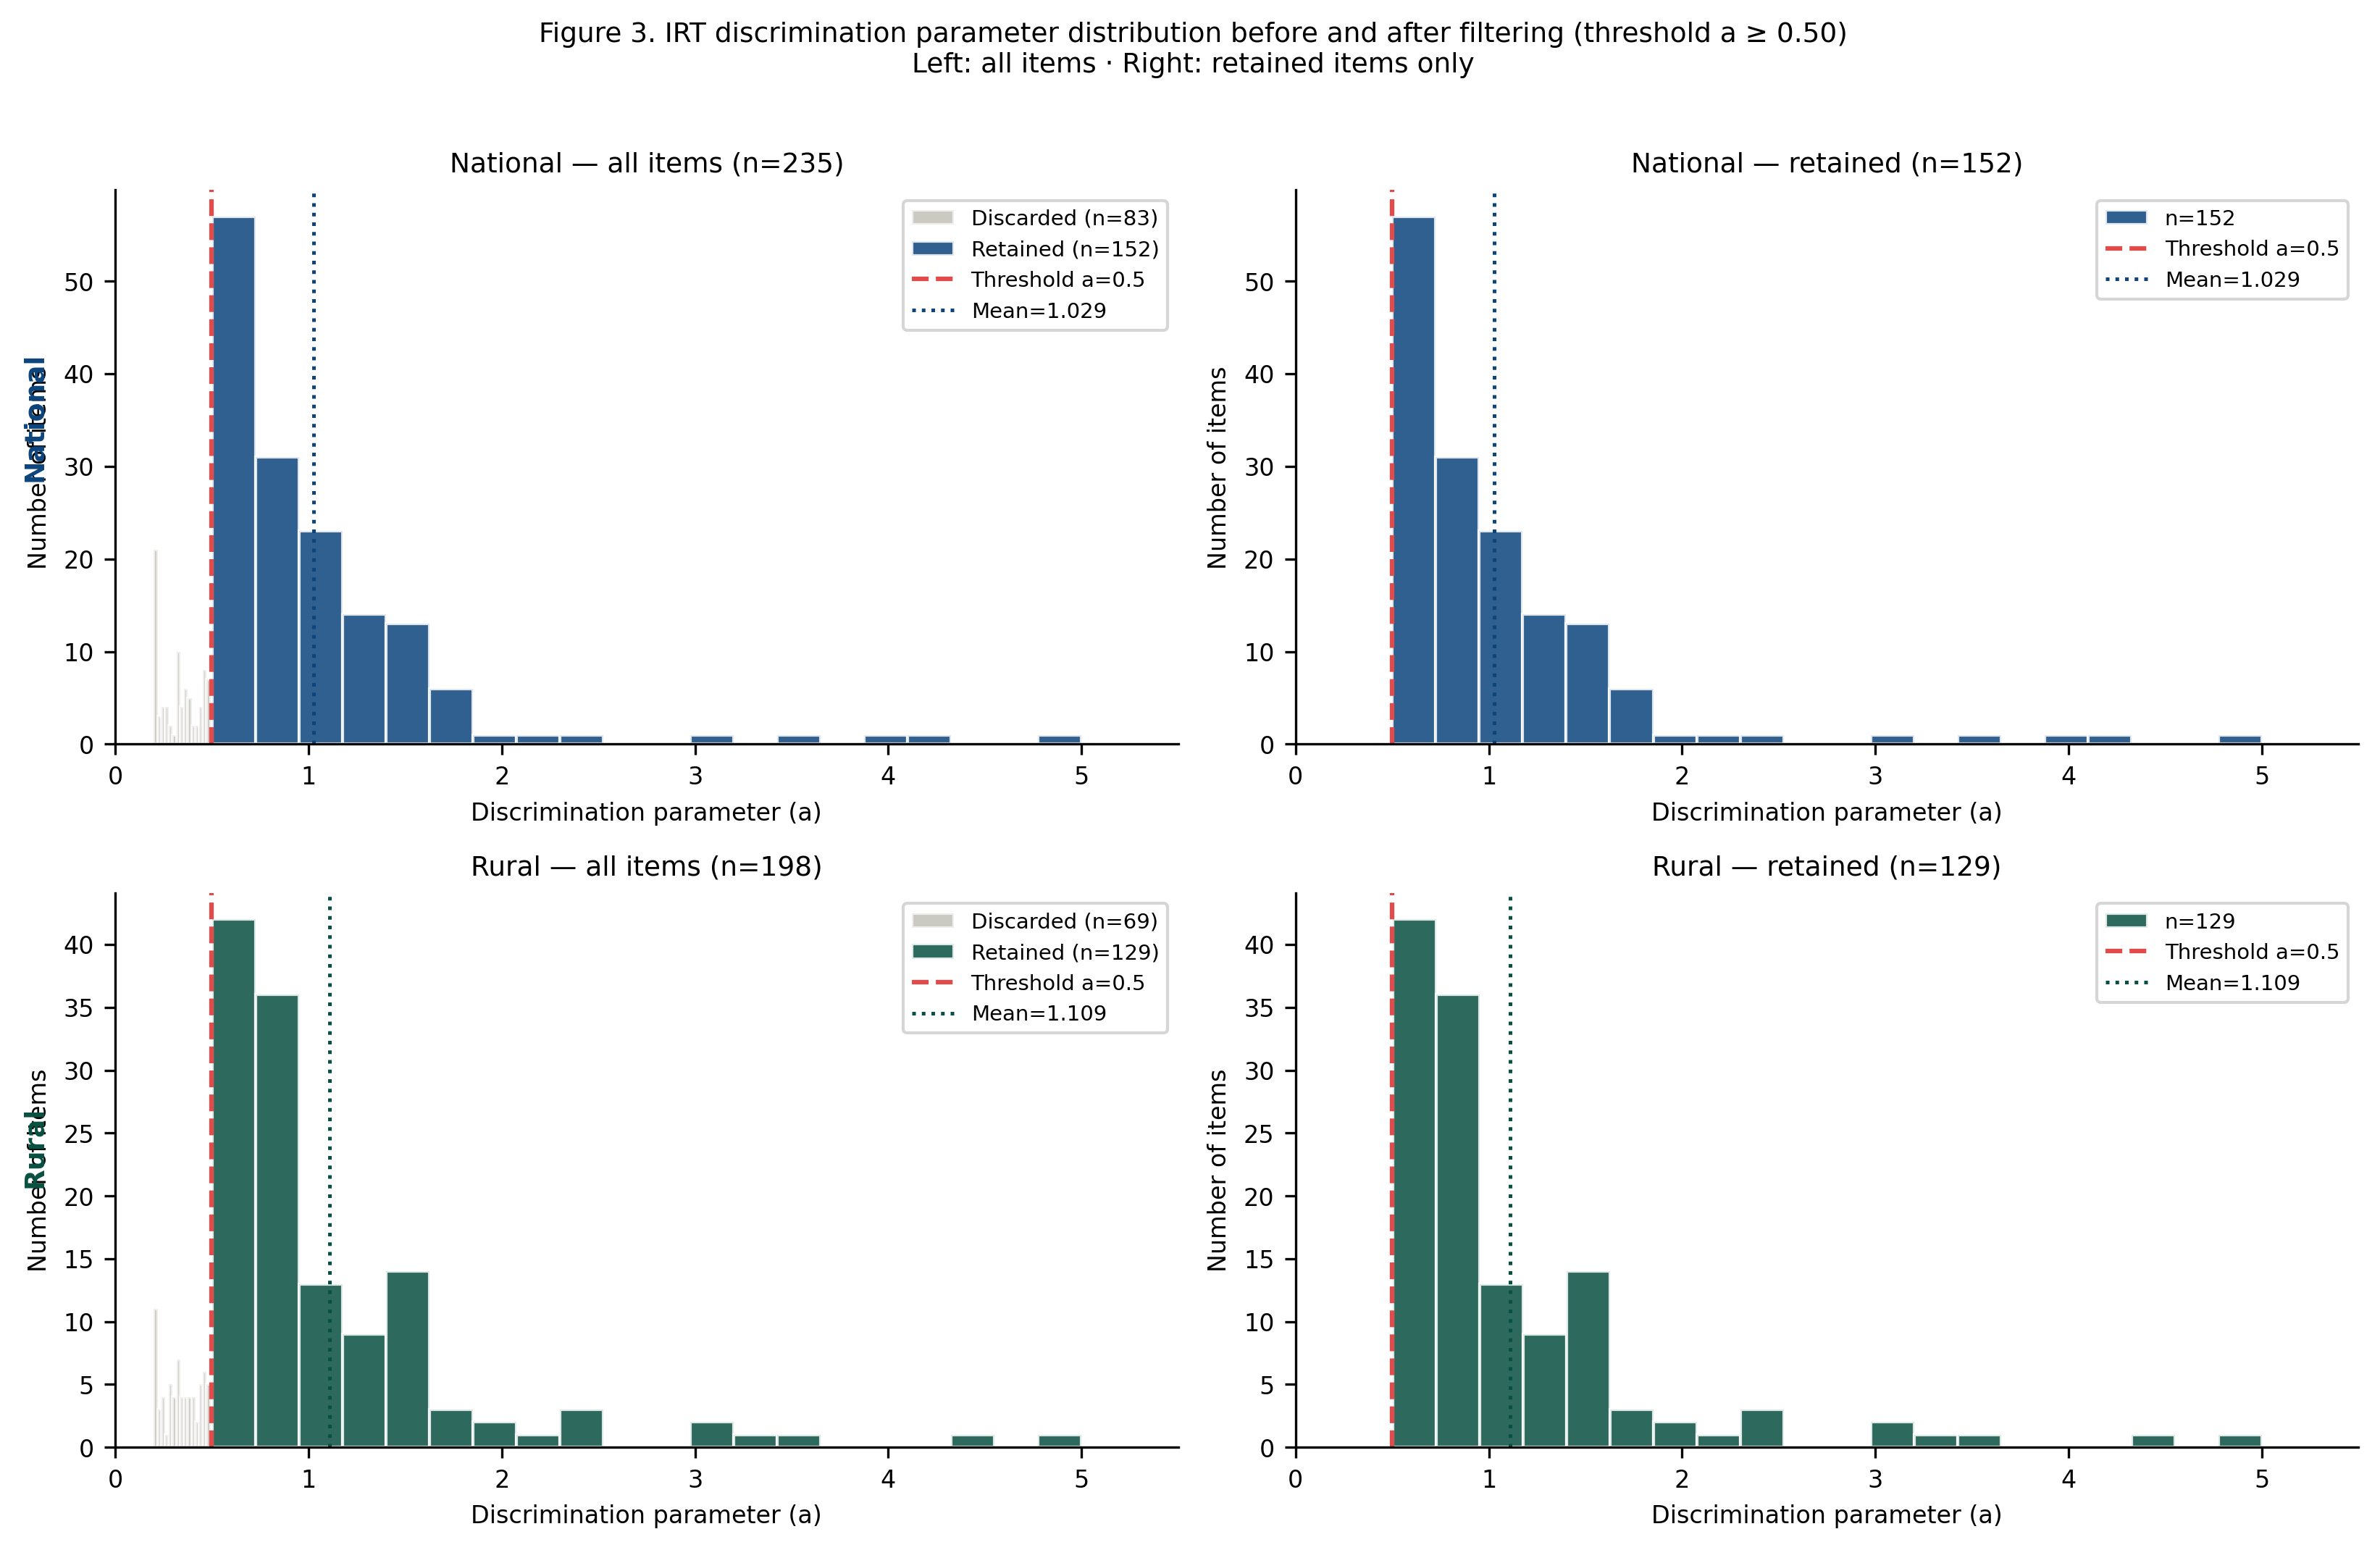

Guardado: /workspace/notebooks_rural/04_graphics/figuras_articulo/fig3_irt_discriminacion_4paneles.png


In [9]:
# ── FIGURA 3 — Distribución del parámetro de discriminación IRT ───────────────
df_irt_rural    = pd.read_csv(RUTA_BASE_RURAL    + "irt_parametros_todos.csv")
df_irt_nacional = pd.read_csv(RUTA_BASE_NACIONAL + "irt_parametros_todos.csv")

UMBRAL = 0.50

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=False)

configs = [
    (axes[0,0], df_irt_nacional, "National — all items (n=235)",  COLOR_NACIONAL, False),
    (axes[0,1], df_irt_nacional, "National — retained (n=152)",   COLOR_NACIONAL, True),
    (axes[1,0], df_irt_rural,    "Rural — all items (n=198)",      COLOR_RURAL,    False),
    (axes[1,1], df_irt_rural,    "Rural — retained (n=129)",       COLOR_RURAL,    True),
]

for ax, df_irt, titulo, color, solo_retenidos in configs:
    if solo_retenidos:
        datos = df_irt[df_irt["discriminacion"] >= UMBRAL]["discriminacion"]
        label_n = f"n={len(datos)}"
        color_barra = color
        alpha = 0.85
    else:
        datos_desc = df_irt[df_irt["discriminacion"] <  UMBRAL]["discriminacion"]
        datos_ret  = df_irt[df_irt["discriminacion"] >= UMBRAL]["discriminacion"]
        ax.hist(datos_desc, bins=15, color="#B4B2A9", alpha=0.7,
                edgecolor="white", label=f"Discarded (n={len(datos_desc)})")
        datos = df_irt["discriminacion"]
        label_n = f"n={len(datos)}"

    ax.hist(
        df_irt[df_irt["discriminacion"] >= UMBRAL]["discriminacion"] if not solo_retenidos
        else datos,
        bins=20, color=color, alpha=0.85, edgecolor="white",
        label=f"Retained (n={len(df_irt[df_irt['discriminacion'] >= UMBRAL])})"
        if not solo_retenidos else f"n={len(datos)}"
    )

    ax.axvline(UMBRAL, color="#E24B4A", linewidth=1.5,
               linestyle="--", label=f"Threshold a={UMBRAL}")
    media = df_irt[df_irt["discriminacion"] >= UMBRAL]["discriminacion"].mean() \
            if not solo_retenidos else datos.mean()
    ax.axvline(media, color=color, linewidth=1.2,
               linestyle=":", label=f"Mean={media:.3f}")

    ax.set_title(titulo, fontsize=9)
    ax.set_xlabel("Discrimination parameter (a)", fontsize=8)
    ax.set_ylabel("Number of items", fontsize=8)
    ax.legend(fontsize=7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(0, 5.5)

# Etiquetas de fila
fig.text(0.01, 0.75, "National", va="center", rotation="vertical",
         fontsize=9, color=COLOR_NACIONAL, fontweight="bold")
fig.text(0.01, 0.27, "Rural", va="center", rotation="vertical",
         fontsize=9, color=COLOR_RURAL, fontweight="bold")

fig.suptitle(
    "Figure 3. IRT discrimination parameter distribution before and after filtering "
    "(threshold a ≥ 0.50)\nLeft: all items · Right: retained items only",
    fontsize=9, y=1.01
)
plt.tight_layout()
ruta_fig = RUTA_FIGURAS + "fig3_irt_discriminacion_4paneles.png"
plt.savefig(ruta_fig)
plt.show()
print(f"Guardado: {ruta_fig}")

## FIGURA 4 — Criterios de selección del modelo LCA (rural)

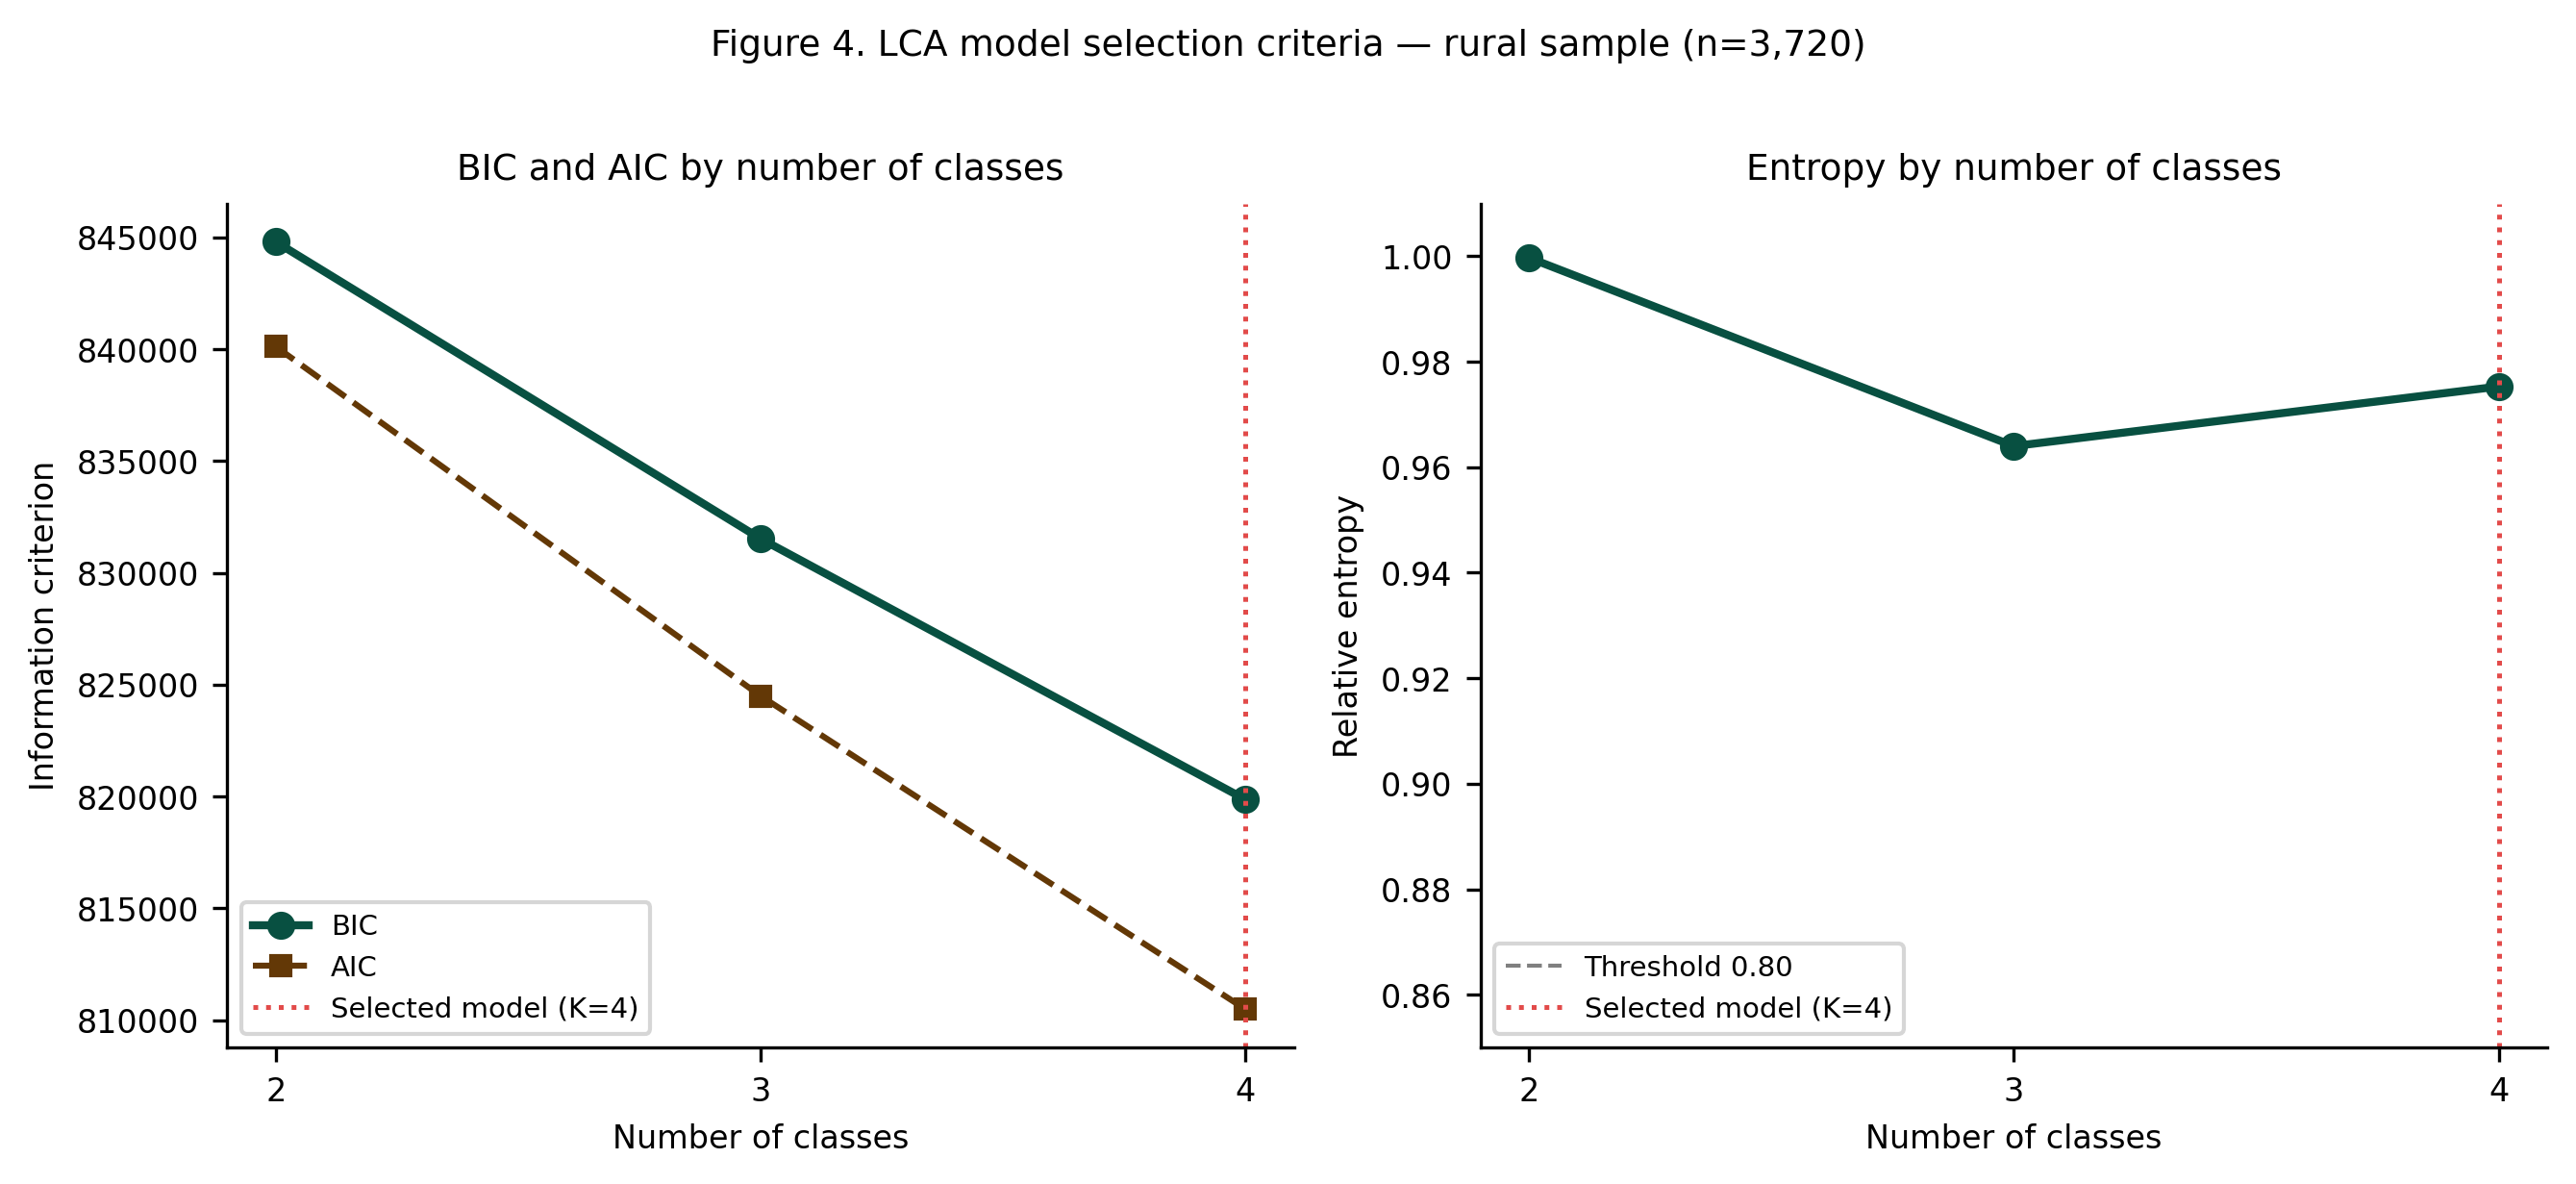

Guardado: /workspace/notebooks_rural/04_graphics/figuras_articulo/fig4_lca_bic_entropia_rural.png


In [11]:
df_ajuste = pd.read_csv(RUTA_BASE_RURAL + "lca_resumen_ajuste.csv")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

clases = df_ajuste["n_clases"].values
n_opt  = int(df_ajuste.loc[df_ajuste["BIC"].idxmin(), "n_clases"])
N_FINAL = 4  # modelo seleccionado

# BIC y AIC
axes[0].plot(clases, df_ajuste["BIC"], "o-", color=COLOR_RURAL,
             linewidth=2, markersize=6, label="BIC")
axes[0].plot(clases, df_ajuste["AIC"], "s--", color=COLOR_ACCENT,
             linewidth=1.5, markersize=5, label="AIC")
axes[0].axvline(N_FINAL, color="#E24B4A", linewidth=1.2,
                linestyle=":", label=f"Selected model (K={N_FINAL})")
axes[0].set_xlabel("Number of classes", fontsize=8)
axes[0].set_ylabel("Information criterion", fontsize=8)
axes[0].set_title("BIC and AIC by number of classes", fontsize=9)
axes[0].legend(fontsize=7)
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].set_xticks(clases)

# Entropía
axes[1].plot(clases, df_ajuste["Entropía"], "o-", color=COLOR_RURAL,
             linewidth=2, markersize=6)
axes[1].axhline(0.80, color="gray", linewidth=1,
                linestyle="--", label="Threshold 0.80")
axes[1].axvline(N_FINAL, color="#E24B4A", linewidth=1.2,
                linestyle=":", label=f"Selected model (K={N_FINAL})")
axes[1].set_xlabel("Number of classes", fontsize=8)
axes[1].set_ylabel("Relative entropy", fontsize=8)
axes[1].set_title("Entropy by number of classes", fontsize=9)
axes[1].set_ylim(0.85, 1.01)
axes[1].legend(fontsize=7)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].set_xticks(clases)

fig.suptitle(
    "Figure 4. LCA model selection criteria — rural sample (n=3,720)",
    fontsize=9, y=1.01
)
plt.tight_layout()
ruta_fig = RUTA_FIGURAS + "fig4_lca_bic_entropia_rural.png"
plt.savefig(ruta_fig)
plt.show()
print(f"Guardado: {ruta_fig}")

## FIGURA 5 — Heatmap de perfiles de clases latentes (rural)

In [12]:
df_perfiles = pd.read_csv(RUTA_BASE_RURAL + "tabla_perfiles_clases.csv", index_col=0)

# El CSV tiene factores como filas y clases como columnas
# Verificar orientación
print("Shape:", df_perfiles.shape)
print("Columnas (primeras 4):", df_perfiles.columns.tolist()[:4])
print("Índice (primeras 4):", df_perfiles.index.tolist()[:4])

Shape: (31, 4)
Columnas (primeras 4): ['Clase 1 — Rendimiento destacado', 'Clase 2 — Rendimiento medio', 'Clase 3 — Rendimiento medio-bajo', 'Clase 4 — Rendimiento bajo']
Índice (primeras 4): ['Capital cultural y recursos del hogar', 'Estrategias de aprendizaje matematico', 'Recursos digitales del hogar', 'Sentido de pertenencia escolar']


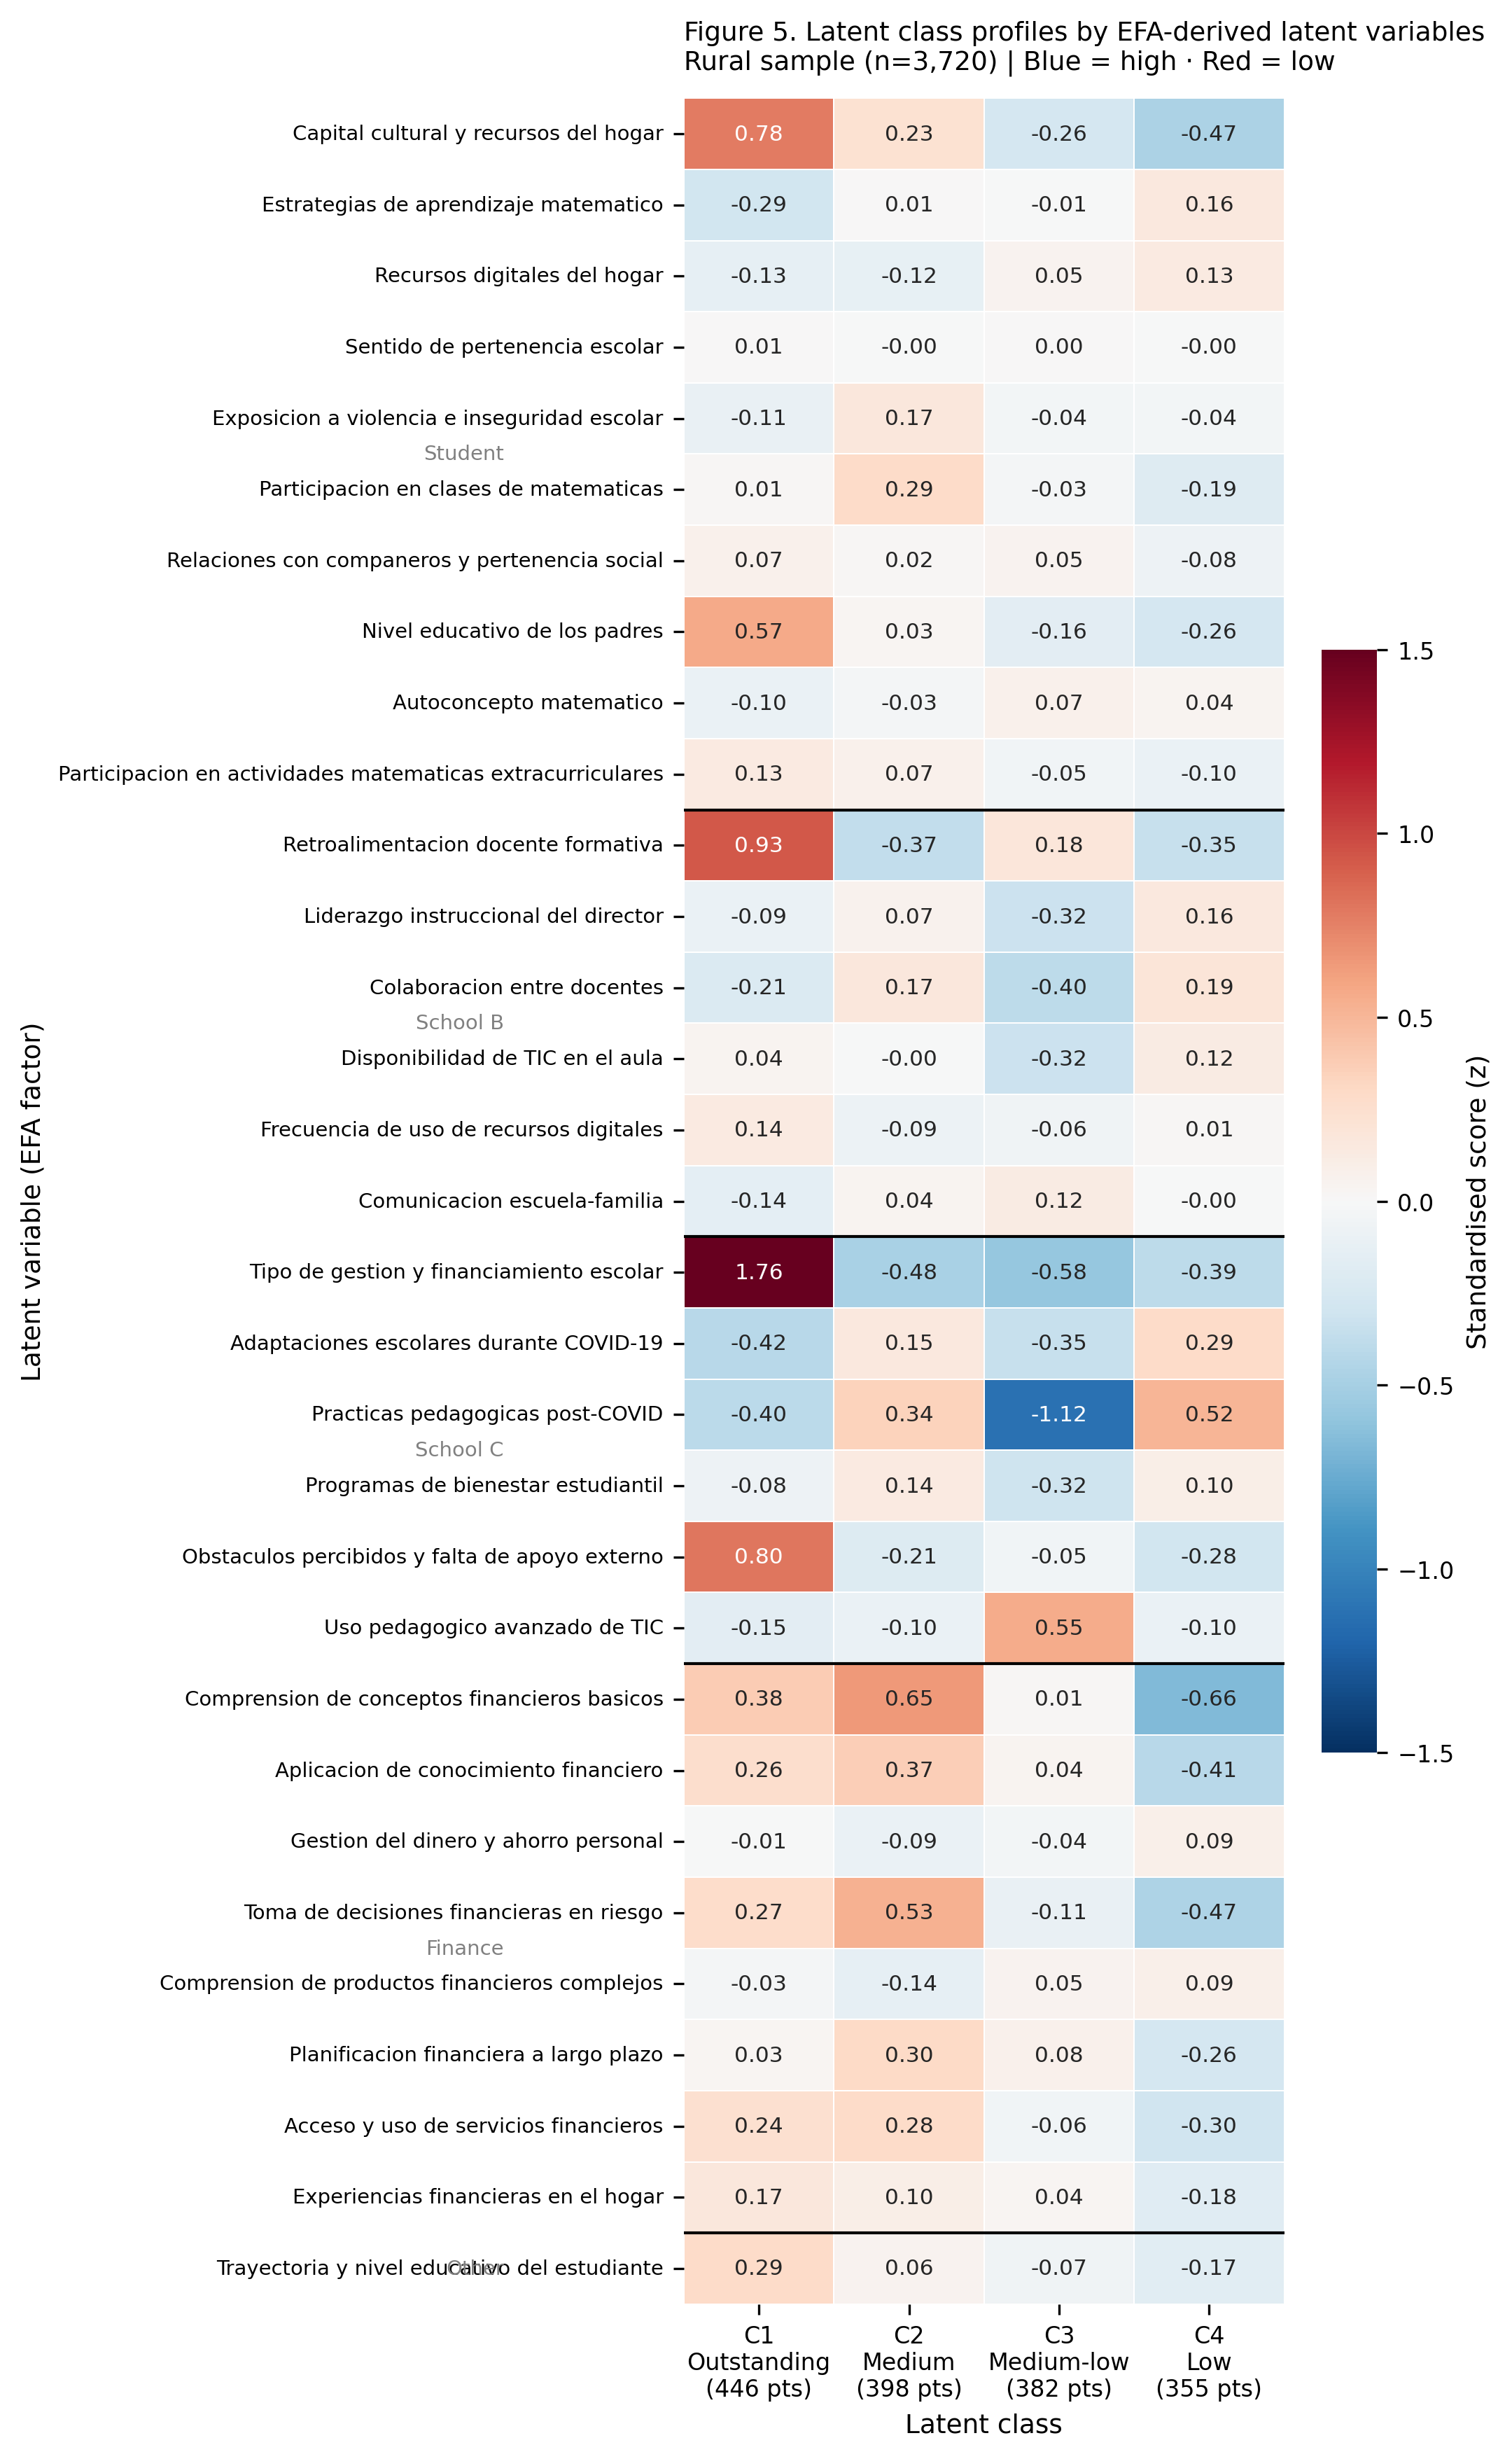

In [17]:
# Abreviar etiquetas de clase para el eje X
mapa_cols = {
    "Clase 1 — Rendimiento destacado" : "C1\nOutstanding\n(446 pts)",
    "Clase 2 — Rendimiento medio"     : "C2\nMedium\n(398 pts)",
    "Clase 3 — Rendimiento medio-bajo": "C3\nMedium-low\n(382 pts)",
    "Clase 4 — Rendimiento bajo"      : "C4\nLow\n(355 pts)",
}
df_plot = df_perfiles.copy()
df_plot.columns = [mapa_cols.get(c, c) for c in df_plot.columns]

altura = max(10, df_plot.shape[0] * 0.38)
fig, ax = plt.subplots(figsize=(7, altura))

sns.heatmap(
    df_plot.astype(float),
    annot=True, fmt=".2f",
    cmap="RdBu_r", center=0,
    vmin=-1.5, vmax=1.5,
    linewidths=0.4, linecolor="white",
    annot_kws={"size": 7.5},
    cbar_kws={"label": "Standardised score (z)", "shrink": 0.5},
    ax=ax,
)

ax.set_title(
    "Figure 5. Latent class profiles by EFA-derived latent variables\n"
    "Rural sample (n=3,720) | Blue = high · Red = low",
    fontsize=9, pad=10, loc="left"
)
ax.set_xlabel("Latent class", fontsize=9)
ax.set_ylabel("Latent variable (EFA factor)", fontsize=9)
ax.tick_params(axis="x", labelsize=8, rotation=0)
ax.tick_params(axis="y", labelsize=7)

# Separadores por bloque
CONTEO_BLOQUES = {
    "Student"   : 10,
    "School B"  : 6,
    "School C"  : 6,
    "Finance"   : 8,
    "Other"     : 1,
}
pos = 0
for bloque, n in CONTEO_BLOQUES.items():
    if n > 0 and pos > 0:
        ax.axhline(pos, color="black", linewidth=1.0)
    if n > 0:
        ax.text(-0.3, pos + n/2, bloque, va="center", ha="right",
                fontsize=7, color="gray", transform=ax.get_yaxis_transform())
    pos += n

plt.tight_layout()
# ruta_fig = RUTA_FIGURAS + "fig5_heatmap_perfiles_clases_rural.png"
# plt.savefig(ruta_fig)
# plt.show()
# print(f"Guardado: {ruta_fig}")

## FIGURA 6 — Contexto de clases (tipo de escuela y comunidad)

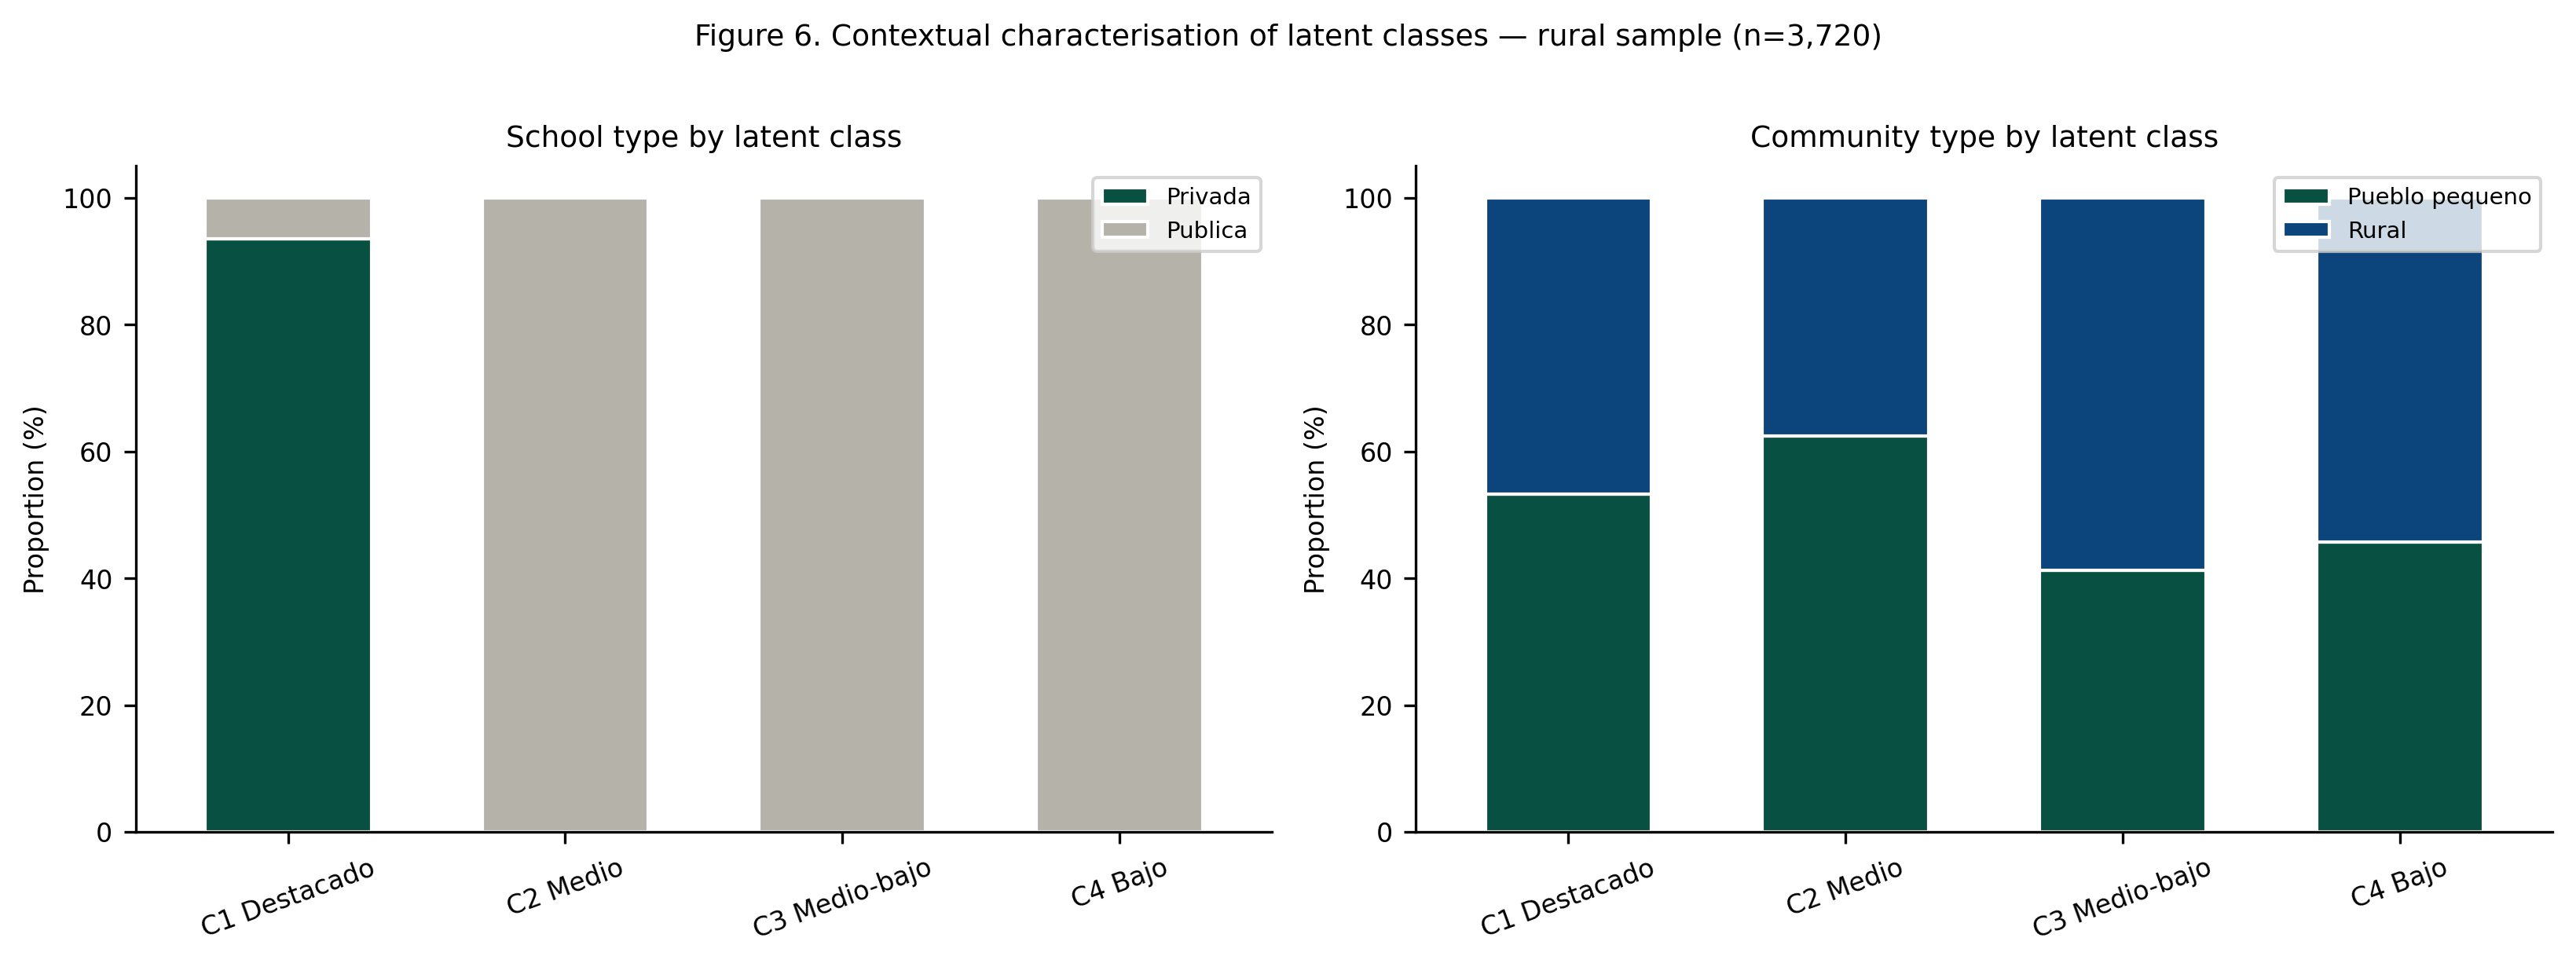

Guardado: /workspace/notebooks_rural/04_graphics/figuras_articulo/fig6_contexto_clases_rural.png


In [14]:
df_escuela   = pd.read_csv(RUTA_BASE_RURAL + "tabla_contexto_escuela.csv",   index_col=0)
df_comunidad = pd.read_csv(RUTA_BASE_RURAL + "tabla_contexto_comunidad.csv", index_col=0)

# Abreviar etiquetas de clase
mapa_idx = {
    "Clase 1 — Rendimiento destacado" : "C1 Destacado",
    "Clase 2 — Rendimiento medio"     : "C2 Medio",
    "Clase 3 — Rendimiento medio-bajo": "C3 Medio-bajo",
    "Clase 4 — Rendimiento bajo"      : "C4 Bajo",
}
df_escuela.index   = [mapa_idx.get(i, i) for i in df_escuela.index]
df_comunidad.index = [mapa_idx.get(i, i) for i in df_comunidad.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Tipo de escuela
colores_escuela = [COLOR_RURAL, "#B4B2A9"]
df_escuela.plot(
    kind="bar", stacked=True, ax=axes[0],
    color=colores_escuela, edgecolor="white", width=0.6
)
axes[0].set_title("School type by latent class", fontsize=9)
axes[0].set_xlabel("")
axes[0].set_ylabel("Proportion (%)", fontsize=8)
axes[0].tick_params(axis="x", rotation=20, labelsize=8)
axes[0].legend(fontsize=7, loc="upper right")
axes[0].spines[["top", "right"]].set_visible(False)

# Tipo de comunidad
colores_comunidad = [COLOR_RURAL, COLOR_NACIONAL]
df_comunidad.plot(
    kind="bar", stacked=True, ax=axes[1],
    color=colores_comunidad, edgecolor="white", width=0.6
)
axes[1].set_title("Community type by latent class", fontsize=9)
axes[1].set_xlabel("")
axes[1].set_ylabel("Proportion (%)", fontsize=8)
axes[1].tick_params(axis="x", rotation=20, labelsize=8)
axes[1].legend(fontsize=7)
axes[1].spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Figure 6. Contextual characterisation of latent classes — rural sample (n=3,720)",
    fontsize=9, y=1.01
)
plt.tight_layout()
ruta_fig = RUTA_FIGURAS + "fig6_contexto_clases_rural.png"
plt.savefig(ruta_fig)
plt.show()
print(f"Guardado: {ruta_fig}")

## FIGURA 7 — Comparativa nacional vs rural (rendimiento y clases)

In [ ]:
# Datos de rendimiento por clase — nacional
rend_nacional = pd.DataFrame({
    "clase"  : ["C1", "C2", "C3", "C4", "C5", "C6", "C7"],
    "media"  : [467.0, 444.6, 433.5, 431.8, 403.5, 373.7, 352.9],
    "sd"     : [71.2, 67.0, 66.1, 76.2, 65.9, 64.3, 57.5],
    "n"      : [679, 1027, 630, 574, 1487, 1070, 1501],
    "muestra": "National"
})

# Datos de rendimiento por clase — rural
rend_rural = pd.DataFrame({
    "clase"  : ["C1", "C2", "C3", "C4"],
    "media"  : [446.2, 398.3, 382.2, 354.7],
    "sd"     : [70.3, 67.7, 70.3, 59.0],
    "n"      : [768, 938, 639, 1375],
    "muestra": "Rural"
})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Panel izquierdo — scores por clase
x_nac   = np.arange(len(rend_nacional))
x_rur   = np.arange(len(rend_rural))

axes[0].barh(x_nac, rend_nacional["media"],
             xerr=rend_nacional["sd"] / np.sqrt(rend_nacional["n"]),
             color=COLOR_NACIONAL, alpha=0.85, capsize=4,
             height=0.5, label="National (7 classes)")
axes[0].set_yticks(x_nac)
axes[0].set_yticklabels(rend_nacional["clase"], fontsize=8)
axes[0].set_xlabel("Mean PISA score", fontsize=8)
axes[0].set_title("National sample — 7 latent classes", fontsize=9)
axes[0].axvline(500, color="gray", linewidth=0.8, linestyle="--", label="OECD mean (500)")
axes[0].axvline(rend_nacional["media"].mean(), color=COLOR_NACIONAL,
                linewidth=0.8, linestyle=":", label=f"Sample mean ({rend_nacional['media'].mean():.0f})")
axes[0].legend(fontsize=7)
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].set_xlim(300, 540)

axes[1].barh(x_rur, rend_rural["media"],
             xerr=rend_rural["sd"] / np.sqrt(rend_rural["n"]),
             color=COLOR_RURAL, alpha=0.85, capsize=4,
             height=0.5, label="Rural (4 classes)")
axes[1].set_yticks(x_rur)
axes[1].set_yticklabels(rend_rural["clase"], fontsize=8)
axes[1].set_xlabel("Mean PISA score", fontsize=8)
axes[1].set_title("Rural subsample — 4 latent classes", fontsize=9)
axes[1].axvline(500, color="gray", linewidth=0.8, linestyle="--", label="OECD mean (500)")
axes[1].axvline(rend_rural["media"].mean(), color=COLOR_RURAL,
                linewidth=0.8, linestyle=":", label=f"Sample mean ({rend_rural['media'].mean():.0f})")
axes[1].legend(fontsize=7)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].set_xlim(300, 540)

fig.suptitle(
    "Figure 7. Mean PISA score by latent class — national vs rural sample",
    fontsize=9, y=1.01
)
plt.tight_layout()
ruta_fig = RUTA_FIGURAS + "fig7_comparativa_nacional_rural.png"
plt.savefig(ruta_fig)
plt.show()
print(f"Guardado: {ruta_fig}")

## Resumen de figuras generadas

In [ ]:
import os
figuras = sorted(os.listdir(RUTA_FIGURAS))
print(f"Total figuras generadas: {len(figuras)}")
print()
for f in figuras:
    ruta = os.path.join(RUTA_FIGURAS, f)
    size_kb = os.path.getsize(ruta) / 1024
    print(f"  {f:<55} {size_kb:>7.1f} KB")